# Rectified flow on AFHQ-64

Same objective as the CelebA notebook:

    x_t = (1 - t) z + t x1
    target v = x1 - z
    Euler: x_{t+dt} = x_t + v(x_t, t) dt

AFHQ is **Animal Faces-HQ**: cat / dog / wild, ~15k images, already square and
centred at 512x512. Three well-separated modes instead of one continuous face
manifold, which is the whole point here: a kick that crosses a mode boundary
changes the *species*, and that is obvious on screen in a way that "slightly
different face" never is.

What changed from `rf_train_celeba64.ipynb`:

- no `CenterCrop` (AFHQ is already a centred square crop)
- the dataset is cached once as a 64px `uint8` tensor on the GPU, so there is
  no `DataLoader` at all. 15k images is 184 MB and decoding 512px PNGs 175
  times over was the bottleneck
- a pre-flight PCA check: do the three classes actually separate in the top
  principal components? If they do, PC-space kicks will cross classes
- the model stays **unconditional** (`num_classes=None`). Conditioning would
  pin the species, and then a kick could not change it

The architecture still lives in `model.py`, unchanged.

Requires: `pip install datasets`

In [1]:
import math, time, copy
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from model import VelocityNet, to_grid, euler_sample

DEV = torch.device("cuda")
torch.backends.cudnn.benchmark = True
torch.manual_seed(0)

CFG = dict(
    size=64,
    channels=3,
    batch=64,
    steps=40_000,
    lr=2e-4,
    warmup=500,
    ch=64,
    ch_mult=(1, 2, 2, 4),  # 64 -> 32 -> 16 -> 8
    attn_res=(16,8),
    ema_decay=0.9995,
    t_dist="logit_normal",
    amp=True,
    out="rf_afhq64_v2.pt",
)
CFG

{'size': 64,
 'channels': 3,
 'batch': 64,
 'steps': 40000,
 'lr': 0.0002,
 'warmup': 500,
 'ch': 64,
 'ch_mult': (1, 2, 2, 4),
 'attn_res': (16, 8),
 'ema_decay': 0.9995,
 't_dist': 'logit_normal',
 'amp': True,
 'out': 'rf_afhq64_v2.pt'}

## Data

`huggan/AFHQ` is the mirror that downloads without a token. Images are 512x512
PNGs, already cropped to the animal's face, so the only transform needed is a
resize.

Decoding 512px PNGs on every epoch is wasteful when the whole dataset fits in
184 MB at 64px, so this cell resizes once and caches the result to disk. First
run downloads ~5 GB and takes a few minutes; after that it loads in a second.

The `label` column is read if it exists (`cat`, `dog`, `wild`). The labels are
never fed to the model - they are only for the PCA check below and for
labelling things in the viz later.

In [2]:
CACHE = Path(f"afhq{CFG['size']}_uint8.pt")

if CACHE.exists():
    blob = torch.load(CACHE, weights_only=False)
    DATA, LABELS, CLASSES = blob["data"], blob["labels"], blob["classes"]
    print("loaded cache", CACHE)
else:
    from datasets import load_dataset
    from PIL import Image

    ds = load_dataset("huggan/AFHQ", split="train")
    cols = list(ds.features)
    print("columns:", cols)

    img_col = "image" if "image" in cols else cols[0]
    label_col = next((c for c in ("label", "labels", "class") if c in cols), None)
    CLASSES = list(ds.features[label_col].names) if label_col else ["all"]
    print("classes:", CLASSES)

    n = len(ds)
    s = CFG["size"]
    DATA = torch.empty(n, 3, s, s, dtype=torch.uint8)
    LABELS = torch.zeros(n, dtype=torch.long)

    t0 = time.perf_counter()
    for i in range(n):
        row = ds[i]
        im = row[img_col].convert("RGB").resize((s, s), Image.LANCZOS)
        DATA[i] = torch.from_numpy(np.asarray(im)).permute(2, 0, 1)
        if label_col:
            LABELS[i] = row[label_col]
        if (i + 1) % 500 == 0:
            print(f"  {i + 1}/{n}  {time.perf_counter() - t0:.0f}s", end="\r")

    torch.save({"data": DATA, "labels": LABELS, "classes": CLASSES}, CACHE)
    print(f"\ncached {n} images to {CACHE} in {time.perf_counter() - t0:.0f}s")

DATA = DATA.to(DEV)
LABELS = LABELS.to(DEV)
print(f"{DATA.shape[0]} images, {DATA.numel() / 1e6:.0f} MB on {DEV}")
print("per class:", {c: int((LABELS == i).sum()) for i, c in enumerate(CLASSES)})

loaded cache afhq64_uint8.pt
16130 images, 198 MB on cuda
per class: {'cat': 5653, 'dog': 5239, 'wild': 5238}


With the data resident on the GPU a "batch" is just a gather, so the training
loop never waits on anything. Random horizontal flip is the only augmentation,
same as before.

batch: (16, 3, 64, 64) range: -1.0 1.0


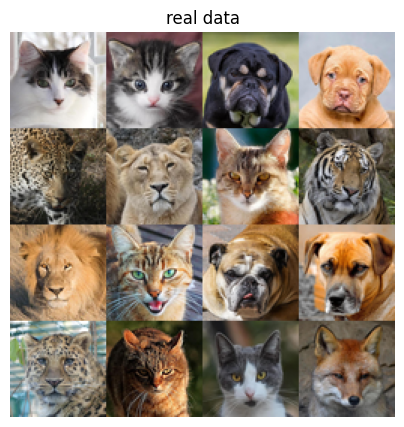

In [5]:
def next_batch(n):
    i = torch.randint(0, DATA.shape[0], (n,), device=DEV)
    x = DATA[i].float().div_(127.5).sub_(1.0)          # uint8 -> [-1, 1]
    flip = torch.rand(n, device=DEV) < 0.5
    x[flip] = x[flip].flip(-1)
    return x


xb = next_batch(16)
print("batch:", tuple(xb.shape), "range:", float(xb.min()), float(xb.max()))

plt.figure(figsize=(5, 5))
plt.imshow(to_grid(xb).cpu().numpy())
plt.axis("off")
plt.title("real data")
plt.show()

## Model and EMA

Unchanged from the CelebA run, including `num_classes=None`. EMA weights are
what you sample from.

One thing to keep an eye on: 40k steps at batch 64 is 2.56M samples, which is
~175 passes over 15k images, against 12 passes on CelebA's 202k. The model will
partly memorise. For this demo that is not really a problem - a sharper, more
sample-like manifold makes the "did the kick leave the manifold" question
*easier* to read, not harder. But the previews are the thing to watch: if they
start looking like exact training images, stop early.

In [7]:
model = VelocityNet(
    in_ch=CFG["channels"],
    size=CFG["size"],
    ch=CFG["ch"],
    ch_mult=CFG["ch_mult"],
    attn_res=CFG["attn_res"],
    num_classes=None,
).to(DEV)
print(f"params: {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M")


class EMA:
    def __init__(self, m, decay):
        self.decay = decay
        self.shadow = copy.deepcopy(m).eval().requires_grad_(False)

    @torch.no_grad()
    def update(self, m):
        for s, p in zip(self.shadow.parameters(), m.parameters()):
            s.lerp_(p.detach(), 1.0 - self.decay)
        for s, b in zip(self.shadow.buffers(), m.buffers()):
            s.copy_(b)


ema = EMA(model, CFG["ema_decay"])

opt = torch.optim.AdamW(
    model.parameters(), lr=CFG["lr"], weight_decay=0.0, betas=(0.9, 0.99)
)
sched = torch.optim.lr_scheduler.LambdaLR(
    opt,
    lambda i: (
        min(1.0, (i + 1) / CFG["warmup"])
        * (0.5 * (1 + math.cos(math.pi * min(1.0, i / CFG["steps"]))))
    ),
)


def sample_t(n, device, mode):
    if mode == "uniform":
        return torch.rand(n, device=device)
    if mode == "logit_normal":
        return torch.sigmoid(torch.randn(n, device=device))
    raise ValueError(mode)

params: 6.72M


## Training loop

Re-running this cell continues from where it stopped, so you can train in
chunks and look at previews in between. Set `CFG["steps"]` to the total you
want and interrupt whenever.

step    250/40000  loss 0.8748  lr 1.00e-04  5.5 it/s
step    500/40000  loss 0.2111  lr 2.00e-04  7.3 it/s
step    750/40000  loss 0.1638  lr 2.00e-04  7.3 it/s
step   1000/40000  loss 0.1541  lr 2.00e-04  7.3 it/s
step   1250/40000  loss 0.1491  lr 2.00e-04  7.2 it/s
step   1500/40000  loss 0.1463  lr 1.99e-04  7.2 it/s
step   1750/40000  loss 0.1436  lr 1.99e-04  7.3 it/s
step   2000/40000  loss 0.1422  lr 1.99e-04  7.1 it/s
step   2250/40000  loss 0.1414  lr 1.98e-04  7.3 it/s
step   2500/40000  loss 0.1390  lr 1.98e-04  7.3 it/s


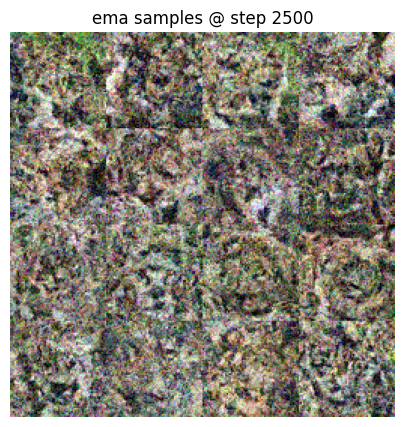

step   2750/40000  loss 0.1382  lr 1.98e-04  6.7 it/s
step   3000/40000  loss 0.1374  lr 1.97e-04  7.3 it/s
step   3250/40000  loss 0.1363  lr 1.97e-04  7.3 it/s
step   3500/40000  loss 0.1364  lr 1.96e-04  7.3 it/s
step   3750/40000  loss 0.1359  lr 1.96e-04  7.3 it/s
step   4000/40000  loss 0.1350  lr 1.95e-04  7.2 it/s
step   4250/40000  loss 0.1344  lr 1.94e-04  7.3 it/s
step   4500/40000  loss 0.1335  lr 1.94e-04  7.2 it/s
step   4750/40000  loss 0.1342  lr 1.93e-04  7.2 it/s
step   5000/40000  loss 0.1333  lr 1.92e-04  7.2 it/s


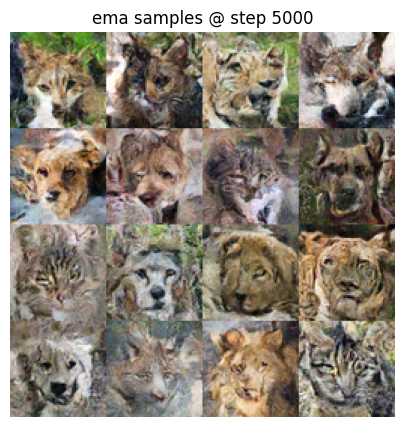

step   5250/40000  loss 0.1322  lr 1.92e-04  7.1 it/s
step   5500/40000  loss 0.1321  lr 1.91e-04  7.3 it/s
step   5750/40000  loss 0.1314  lr 1.90e-04  7.3 it/s
step   6000/40000  loss 0.1317  lr 1.89e-04  7.3 it/s
step   6250/40000  loss 0.1315  lr 1.88e-04  7.3 it/s
step   6500/40000  loss 0.1308  lr 1.87e-04  7.3 it/s
step   6750/40000  loss 0.1306  lr 1.86e-04  7.3 it/s
step   7000/40000  loss 0.1299  lr 1.85e-04  7.2 it/s
step   7250/40000  loss 0.1307  lr 1.84e-04  7.2 it/s
step   7500/40000  loss 0.1300  lr 1.83e-04  7.2 it/s


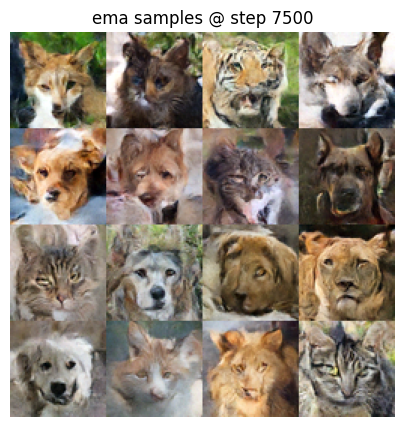

step   7750/40000  loss 0.1292  lr 1.82e-04  7.0 it/s
step   8000/40000  loss 0.1291  lr 1.81e-04  7.2 it/s
step   8250/40000  loss 0.1285  lr 1.80e-04  7.3 it/s
step   8500/40000  loss 0.1290  lr 1.79e-04  7.2 it/s
step   8750/40000  loss 0.1288  lr 1.77e-04  7.3 it/s
step   9000/40000  loss 0.1282  lr 1.76e-04  7.2 it/s
step   9250/40000  loss 0.1281  lr 1.75e-04  7.2 it/s
step   9500/40000  loss 0.1275  lr 1.73e-04  7.3 it/s
step   9750/40000  loss 0.1283  lr 1.72e-04  7.2 it/s
step  10000/40000  loss 0.1277  lr 1.71e-04  7.2 it/s


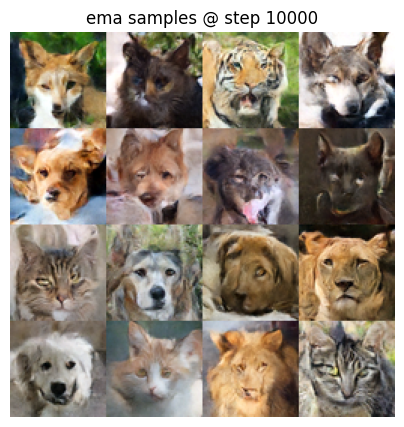

step  10250/40000  loss 0.1270  lr 1.69e-04  7.0 it/s
step  10500/40000  loss 0.1270  lr 1.68e-04  7.2 it/s
step  10750/40000  loss 0.1264  lr 1.66e-04  7.3 it/s
step  11000/40000  loss 0.1269  lr 1.65e-04  7.2 it/s
step  11250/40000  loss 0.1269  lr 1.63e-04  7.3 it/s
step  11500/40000  loss 0.1263  lr 1.62e-04  7.2 it/s
step  11750/40000  loss 0.1261  lr 1.60e-04  7.3 it/s
step  12000/40000  loss 0.1256  lr 1.59e-04  7.3 it/s
step  12250/40000  loss 0.1263  lr 1.57e-04  7.3 it/s
step  12500/40000  loss 0.1258  lr 1.56e-04  7.3 it/s


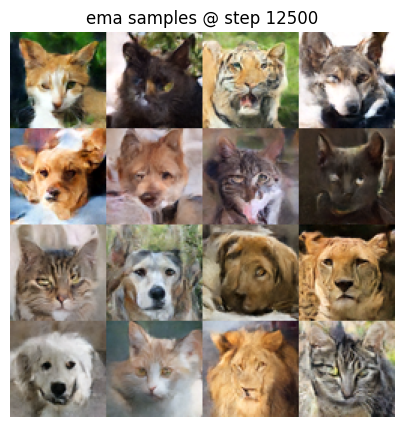

step  12750/40000  loss 0.1251  lr 1.54e-04  7.1 it/s
step  13000/40000  loss 0.1251  lr 1.52e-04  7.2 it/s
step  13250/40000  loss 0.1246  lr 1.51e-04  7.2 it/s
step  13500/40000  loss 0.1251  lr 1.49e-04  7.3 it/s
step  13750/40000  loss 0.1252  lr 1.47e-04  7.2 it/s
step  14000/40000  loss 0.1245  lr 1.45e-04  7.3 it/s
step  14250/40000  loss 0.1244  lr 1.44e-04  7.3 it/s
step  14500/40000  loss 0.1239  lr 1.42e-04  7.3 it/s
step  14750/40000  loss 0.1245  lr 1.40e-04  7.3 it/s
step  15000/40000  loss 0.1241  lr 1.38e-04  7.3 it/s


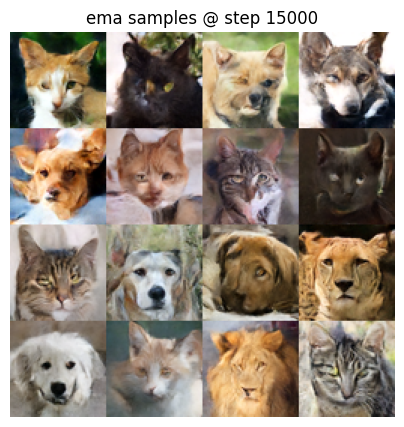

step  15250/40000  loss 0.1234  lr 1.36e-04  7.2 it/s
step  15500/40000  loss 0.1234  lr 1.35e-04  7.3 it/s
step  15750/40000  loss 0.1229  lr 1.33e-04  7.3 it/s
step  16000/40000  loss 0.1236  lr 1.31e-04  7.3 it/s
step  16250/40000  loss 0.1235  lr 1.29e-04  7.3 it/s
step  16500/40000  loss 0.1229  lr 1.27e-04  7.3 it/s
step  16750/40000  loss 0.1228  lr 1.25e-04  7.3 it/s
step  17000/40000  loss 0.1224  lr 1.23e-04  7.3 it/s
step  17250/40000  loss 0.1229  lr 1.21e-04  7.3 it/s
step  17500/40000  loss 0.1226  lr 1.20e-04  7.3 it/s


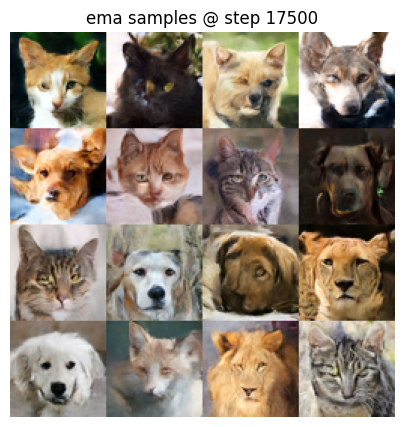

step  17750/40000  loss 0.1219  lr 1.18e-04  7.2 it/s
step  18000/40000  loss 0.1219  lr 1.16e-04  7.3 it/s
step  18250/40000  loss 0.1214  lr 1.14e-04  7.3 it/s
step  18500/40000  loss 0.1220  lr 1.12e-04  7.3 it/s
step  18750/40000  loss 0.1219  lr 1.10e-04  7.3 it/s
step  19000/40000  loss 0.1214  lr 1.08e-04  7.3 it/s
step  19250/40000  loss 0.1214  lr 1.06e-04  7.3 it/s
step  19500/40000  loss 0.1207  lr 1.04e-04  7.3 it/s
step  19750/40000  loss 0.1214  lr 1.02e-04  7.3 it/s
step  20000/40000  loss 0.1211  lr 1.00e-04  7.3 it/s


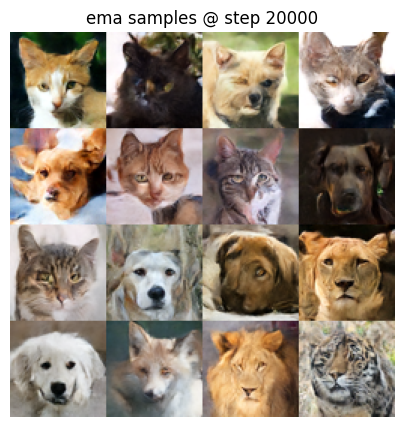

step  20250/40000  loss 0.1205  lr 9.80e-05  7.2 it/s
step  20500/40000  loss 0.1203  lr 9.61e-05  7.3 it/s
step  20750/40000  loss 0.1199  lr 9.41e-05  7.3 it/s
step  21000/40000  loss 0.1206  lr 9.22e-05  7.3 it/s
step  21250/40000  loss 0.1204  lr 9.02e-05  7.3 it/s
step  21500/40000  loss 0.1200  lr 8.82e-05  7.3 it/s
step  21750/40000  loss 0.1199  lr 8.63e-05  7.3 it/s
step  22000/40000  loss 0.1193  lr 8.44e-05  7.3 it/s
step  22250/40000  loss 0.1199  lr 8.24e-05  7.3 it/s
step  22500/40000  loss 0.1195  lr 8.05e-05  7.3 it/s


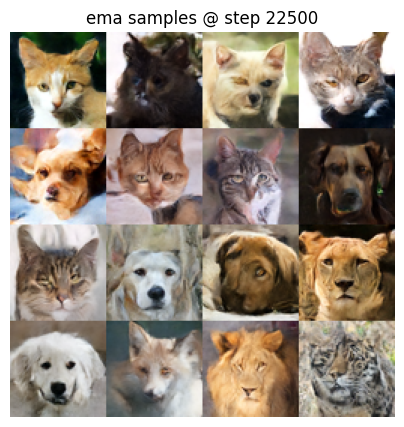

step  22750/40000  loss 0.1190  lr 7.86e-05  7.2 it/s
step  23000/40000  loss 0.1189  lr 7.67e-05  7.3 it/s
step  23250/40000  loss 0.1185  lr 7.48e-05  7.3 it/s
step  23500/40000  loss 0.1191  lr 7.29e-05  7.3 it/s
step  23750/40000  loss 0.1190  lr 7.10e-05  7.3 it/s
step  24000/40000  loss 0.1186  lr 6.91e-05  7.3 it/s
step  24250/40000  loss 0.1184  lr 6.72e-05  7.3 it/s
step  24500/40000  loss 0.1178  lr 6.54e-05  7.3 it/s
step  24750/40000  loss 0.1185  lr 6.36e-05  7.3 it/s
step  25000/40000  loss 0.1182  lr 6.17e-05  7.3 it/s


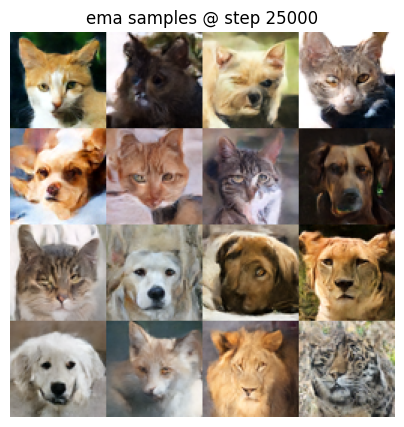

step  25250/40000  loss 0.1176  lr 5.99e-05  7.2 it/s
step  25500/40000  loss 0.1176  lr 5.81e-05  7.3 it/s
step  25750/40000  loss 0.1172  lr 5.64e-05  7.3 it/s
step  26000/40000  loss 0.1177  lr 5.46e-05  7.3 it/s
step  26250/40000  loss 0.1177  lr 5.29e-05  7.3 it/s
step  26500/40000  loss 0.1173  lr 5.11e-05  7.3 it/s
step  26750/40000  loss 0.1172  lr 4.94e-05  7.3 it/s
step  27000/40000  loss 0.1165  lr 4.78e-05  7.3 it/s
step  27250/40000  loss 0.1172  lr 4.61e-05  7.3 it/s
step  27500/40000  loss 0.1169  lr 4.44e-05  7.3 it/s


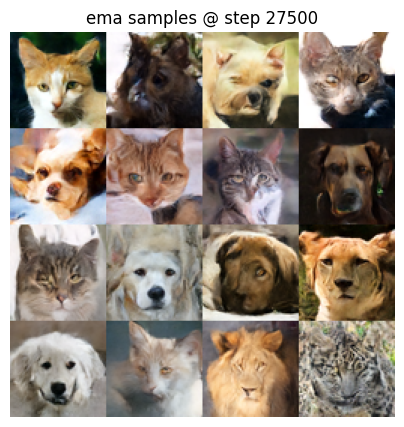

step  27750/40000  loss 0.1164  lr 4.28e-05  7.2 it/s
step  28000/40000  loss 0.1164  lr 4.12e-05  7.3 it/s
step  28250/40000  loss 0.1159  lr 3.96e-05  7.3 it/s
step  28500/40000  loss 0.1165  lr 3.81e-05  7.3 it/s
step  28750/40000  loss 0.1165  lr 3.66e-05  7.3 it/s
step  29000/40000  loss 0.1161  lr 3.51e-05  7.3 it/s
step  29250/40000  loss 0.1160  lr 3.36e-05  7.3 it/s
step  29500/40000  loss 0.1154  lr 3.21e-05  7.3 it/s
step  29750/40000  loss 0.1161  lr 3.07e-05  7.3 it/s
step  30000/40000  loss 0.1159  lr 2.93e-05  7.3 it/s


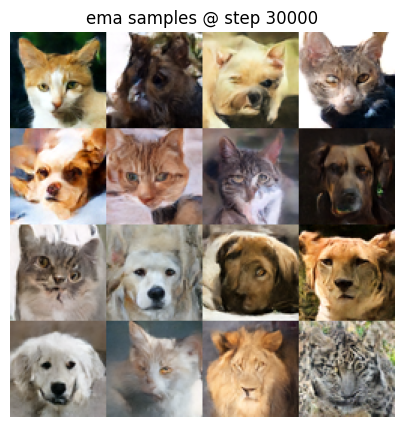

step  30250/40000  loss 0.1154  lr 2.79e-05  7.2 it/s
step  30500/40000  loss 0.1154  lr 2.66e-05  7.3 it/s
step  30750/40000  loss 0.1149  lr 2.52e-05  7.3 it/s
step  31000/40000  loss 0.1155  lr 2.40e-05  7.3 it/s
step  31250/40000  loss 0.1155  lr 2.27e-05  7.3 it/s
step  31500/40000  loss 0.1152  lr 2.15e-05  7.3 it/s
step  31750/40000  loss 0.1152  lr 2.03e-05  7.3 it/s
step  32000/40000  loss 0.1146  lr 1.91e-05  7.3 it/s
step  32250/40000  loss 0.1153  lr 1.80e-05  7.3 it/s
step  32500/40000  loss 0.1150  lr 1.69e-05  7.3 it/s


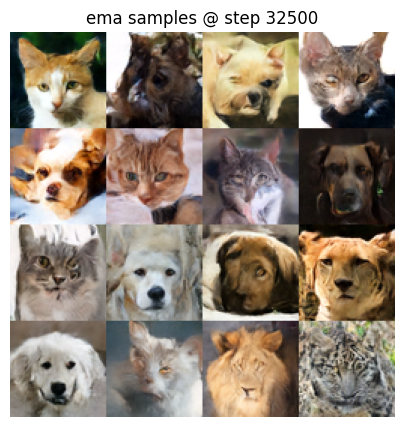

step  32750/40000  loss 0.1146  lr 1.58e-05  7.2 it/s
step  33000/40000  loss 0.1147  lr 1.47e-05  7.3 it/s
step  33250/40000  loss 0.1142  lr 1.37e-05  7.3 it/s
step  33500/40000  loss 0.1149  lr 1.28e-05  7.3 it/s
step  33750/40000  loss 0.1148  lr 1.18e-05  7.3 it/s
step  34000/40000  loss 0.1146  lr 1.09e-05  7.3 it/s
step  34250/40000  loss 0.1146  lr 1.00e-05  7.3 it/s
step  34500/40000  loss 0.1141  lr 9.19e-06  7.3 it/s
step  34750/40000  loss 0.1147  lr 8.38e-06  7.3 it/s
step  35000/40000  loss 0.1145  lr 7.61e-06  7.3 it/s


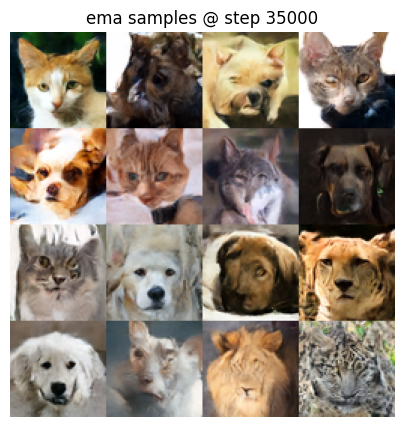

step  35250/40000  loss 0.1142  lr 6.88e-06  7.2 it/s
step  35500/40000  loss 0.1142  lr 6.18e-06  7.3 it/s
step  35750/40000  loss 0.1138  lr 5.52e-06  7.3 it/s
step  36000/40000  loss 0.1146  lr 4.89e-06  7.3 it/s
step  36250/40000  loss 0.1145  lr 4.31e-06  7.3 it/s
step  36500/40000  loss 0.1143  lr 3.75e-06  7.3 it/s
step  36750/40000  loss 0.1144  lr 3.24e-06  7.3 it/s
step  37000/40000  loss 0.1139  lr 2.76e-06  7.3 it/s
step  37250/40000  loss 0.1145  lr 2.32e-06  7.3 it/s
step  37500/40000  loss 0.1144  lr 1.92e-06  7.3 it/s


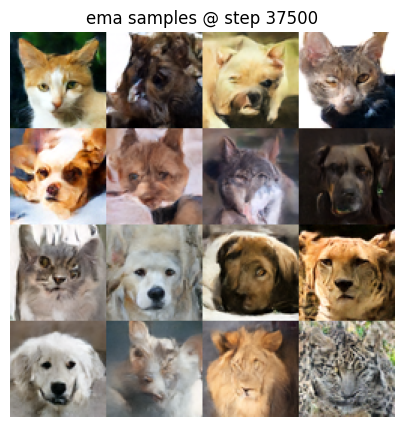

step  37750/40000  loss 0.1140  lr 1.56e-06  7.2 it/s
step  38000/40000  loss 0.1141  lr 1.23e-06  7.3 it/s
step  38250/40000  loss 0.1136  lr 9.43e-07  7.3 it/s
step  38500/40000  loss 0.1145  lr 6.93e-07  7.3 it/s
step  38750/40000  loss 0.1144  lr 4.82e-07  7.3 it/s
step  39000/40000  loss 0.1142  lr 3.08e-07  7.3 it/s
step  39250/40000  loss 0.1142  lr 1.73e-07  7.3 it/s
step  39500/40000  loss 0.1138  lr 7.71e-08  7.3 it/s
step  39750/40000  loss 0.1145  lr 1.93e-08  7.3 it/s
step  40000/40000  loss 0.1143  lr 0.00e+00  7.3 it/s


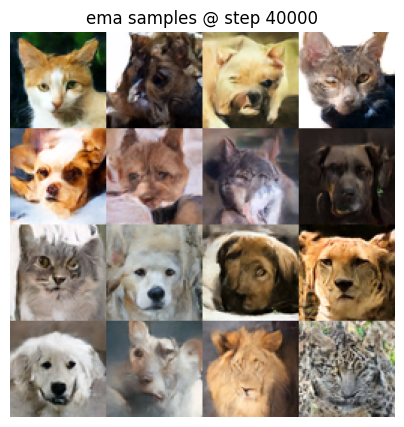

In [8]:
SHAPE = (CFG["channels"], CFG["size"], CFG["size"])
step = globals().get("step", 0)
amp = dict(device_type="cuda", dtype=torch.bfloat16, enabled=CFG["amp"])


def preview(n=16, T=50):
    x = euler_sample(ema.shadow, n, T, DEV, SHAPE, seed=0)
    plt.figure(figsize=(5, 5))
    plt.imshow(to_grid(x).cpu().numpy())
    plt.axis("off")
    plt.title(f"ema samples @ step {step}")
    plt.show()


running, t0 = 0.0, time.perf_counter()
LOG_EVERY, PREVIEW_EVERY = 250, 2500

try:
    while step < CFG["steps"]:
        x1 = next_batch(CFG["batch"])
        z = torch.randn_like(x1)
        t = sample_t(x1.shape[0], DEV, CFG["t_dist"])
        tb = t[:, None, None, None]
        xt = (1 - tb) * z + tb * x1

        with torch.autocast(**amp):
            loss = F.mse_loss(model(xt, t).float(), x1 - z)

        opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        sched.step()
        ema.update(model)

        running += loss.item()
        step += 1

        if step % LOG_EVERY == 0:
            dt = time.perf_counter() - t0
            print(
                f"step {step:>6}/{CFG['steps']}  loss {running / LOG_EVERY:.4f}"
                f"  lr {sched.get_last_lr()[0]:.2e}  {LOG_EVERY / dt:.1f} it/s"
            )
            running, t0 = 0.0, time.perf_counter()

        if step % PREVIEW_EVERY == 0:
            preview()
except KeyboardInterrupt:
    print("interrupted at step", step)

## Save

`meta` is what the viz scripts read to size their buffers. `classes` goes in
too, so a kick demo can name what it is looking at.

In [9]:
torch.save(
    {
        "model": model.state_dict(),
        "ema": ema.shadow.state_dict(),
        "config": model.cfg,
        "meta": {
            "channels": CFG["channels"],
            "size": CFG["size"],
            "num_classes": None,
            "classes": CLASSES,
            "name": "afhq64",
        },
        "step": step,
    },
    CFG["out"],
)
print("saved", CFG["out"], "at step", step)

saved rf_afhq64_v2.pt at step 40000


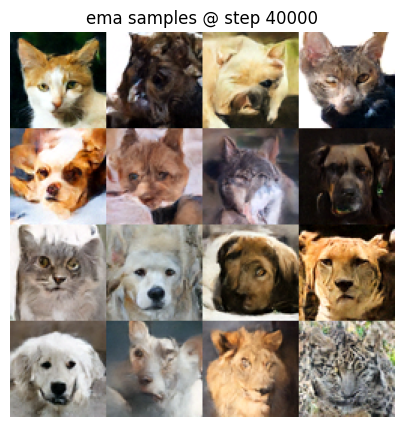

In [10]:
# final look, more Euler steps
preview(n=16, T=1_000)

In [ ]:
hh